### This notebook helps to compute an amount of Freznel zone
Also that computes a beginning of relative linear pattern 

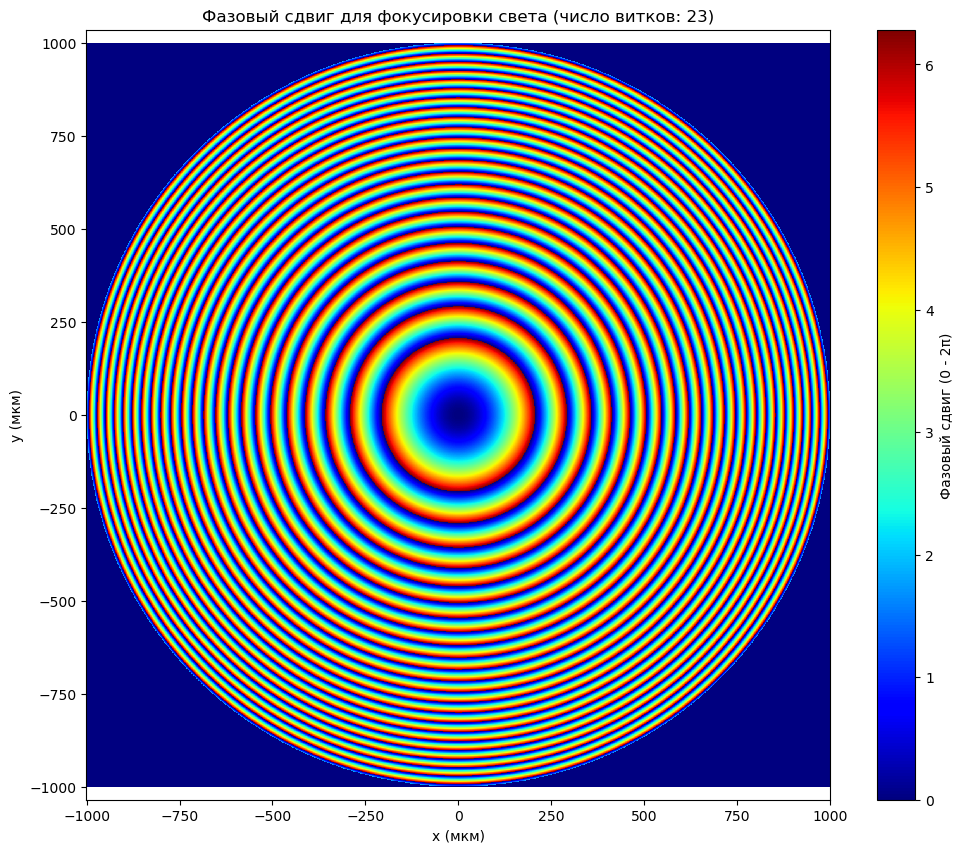

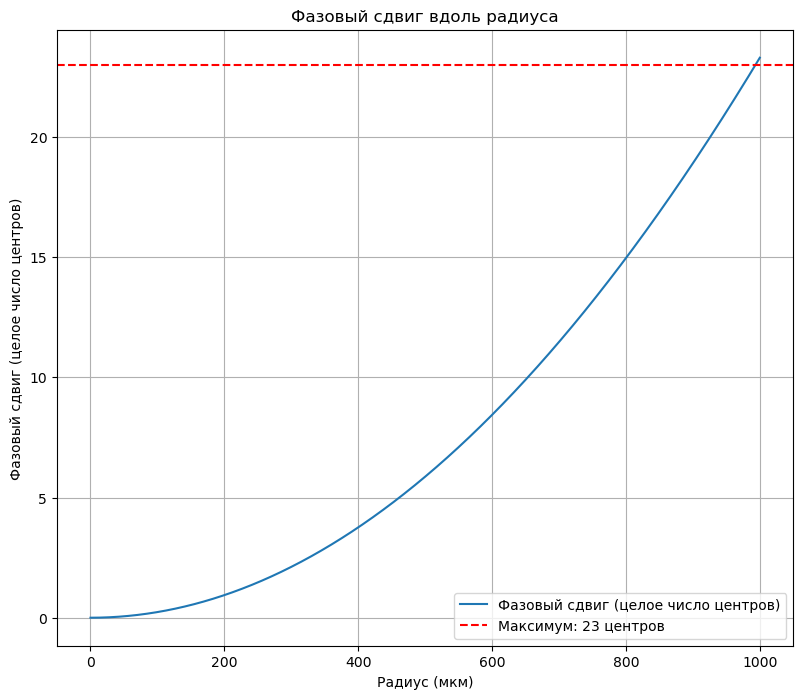

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Параметры задачи
wavelength = 4.25e-6  # длина волны, м
focal_length = 5 * 1e-3  # фокусное расстояние, м
aperture_diameter = 2 * 1e-3  # диаметр апертуры, м

# Генерация координат на плоскости
num_points = 1920  # количество точек для расчётов
x = np.linspace(-aperture_diameter / 2, aperture_diameter / 2, num_points)
y = np.linspace(-aperture_diameter / 2, aperture_diameter / 2, num_points)
x, y = np.meshgrid(x, y)
r = np.sqrt(x**2 + y**2)

# Расчёт фазового сдвига
phase_shift = (2 * np.pi / wavelength) * (np.sqrt(r**2 + focal_length**2) - focal_length)

# Нормировка фазового сдвига в диапазон [0, 2*pi]
phase_shift = np.mod(phase_shift, 2 * np.pi)

# Маска апертуры (для ограничений по диаметру)
aperture_mask = r <= (aperture_diameter / 2)
phase_shift *= aperture_mask

# Подсчёт числа полных фазовых сдвигов вдоль радиуса
r_line = np.linspace(0, aperture_diameter / 2, num_points)
phase_along_radius = (2 * np.pi / wavelength) * (np.sqrt(r_line**2 + focal_length**2) - focal_length)
phase_cycles = np.floor(phase_along_radius / (2 * np.pi))
max_phase_cycles = int(phase_cycles[-1])

# Найдем максимальную производную dy/dx
derivative_max = np.max

# Построение графика фазового сдвига
plt.figure(figsize=(12, 10))
plt.pcolormesh(x * 1e6, y * 1e6, phase_shift, shading='auto', cmap='jet')
plt.colorbar(label='Фазовый сдвиг (0 - 2π)')
plt.title(f'Фазовый сдвиг для фокусировки света (число витков: {max_phase_cycles})')
plt.xlabel('x (мкм)')
plt.ylabel('y (мкм)')
plt.axis('equal')
plt.show()

# Построение графика фазового сдвига вдоль радиуса
plt.figure(figsize=(9.5, 8))
plt.plot(r_line * 1e6, phase_along_radius / (2 * np.pi), label='Фазовый сдвиг (целое число центров)')
plt.axhline(y=max_phase_cycles, color='r', linestyle='--', label=f'Максимум: {max_phase_cycles} центров')
plt.title('Фазовый сдвиг вдоль радиуса')
plt.xlabel('Радиус (мкм)')
plt.ylabel('Фазовый сдвиг (целое число центров)')
plt.legend()
plt.grid()
plt.show()

The beginning of the linear area: r = 2600.31 microns
The beginning of the linear area: the center number = 18


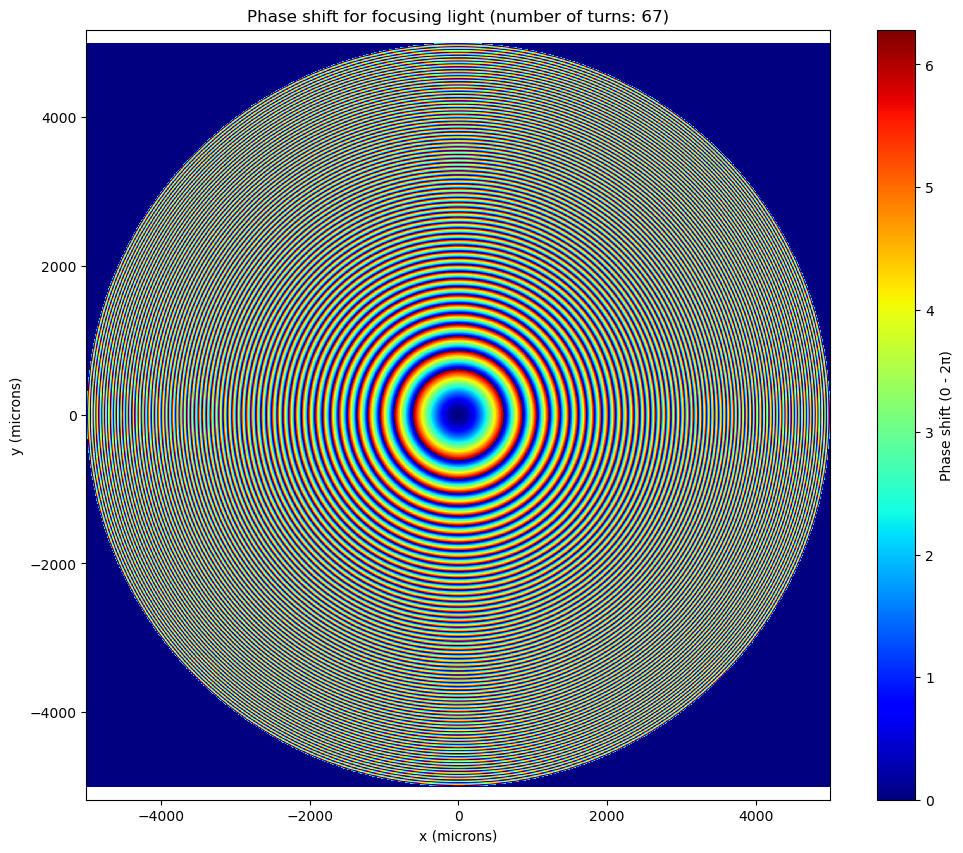

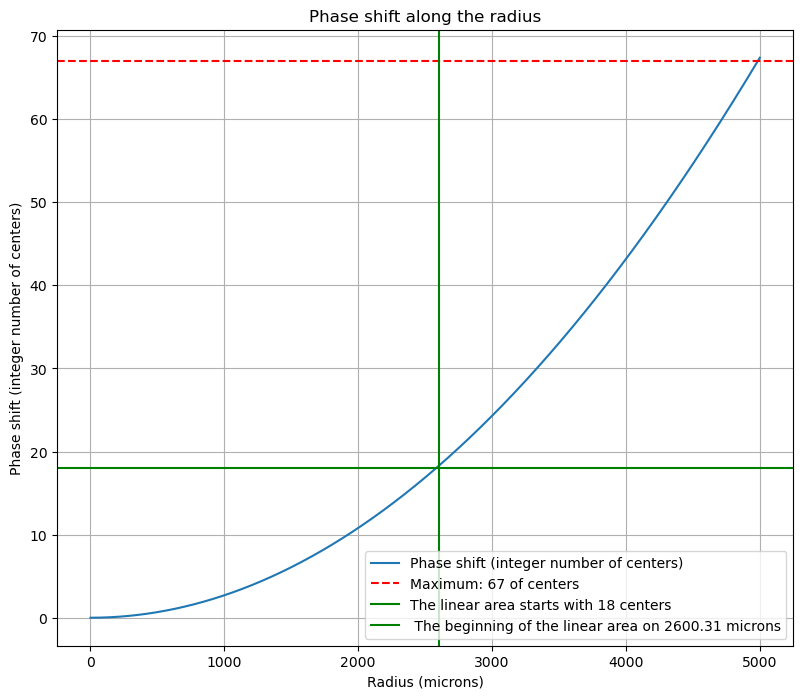

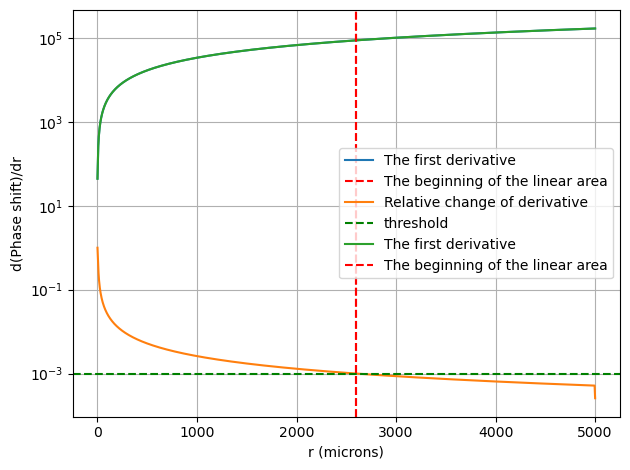

In [4]:
import numpy as np
import matplotlib.pyplot as plt

# Параметры задачи
wavelength = 3.7e-6  # длина волны, м
focal_length = 50e-3  # фокусное расстояние, м
aperture_diameter = 10e-3  # диаметр апертуры, м

# Генерация координат на плоскости
num_points = 1920  # количество точек для расчётов
x = np.linspace(-aperture_diameter / 2, aperture_diameter / 2, num_points)
y = np.linspace(-aperture_diameter / 2, aperture_diameter / 2, num_points)
x, y = np.meshgrid(x, y)
r = np.sqrt(x**2 + y**2)

# Расчёт фазового сдвига
phase_shift = (2 * np.pi / wavelength) * (np.sqrt(r**2 + focal_length**2) - focal_length)

# Нормировка фазового сдвига в диапазон [0, 2*pi]
phase_shift = np.mod(phase_shift, 2 * np.pi)

# Маска апертуры (для ограничений по диаметру)
aperture_mask = r <= (aperture_diameter / 2)
phase_shift *= aperture_mask

# Подсчёт числа полных фазовых сдвигов вдоль радиуса
r_line = np.linspace(0, aperture_diameter / 2, num_points)
phase_along_radius = (2 * np.pi / wavelength) * (np.sqrt(r_line**2 + focal_length**2) - focal_length)
phase_cycles = np.floor(phase_along_radius / (2 * np.pi))
max_phase_cycles = int(phase_cycles[-1])

# Вычисляем численную производную
d_phase_dr = np.gradient(phase_along_radius, r_line)

# Нормируем изменение производной
relative_change = np.abs(np.gradient(d_phase_dr)) / np.abs(d_phase_dr)

# Определяем порог для изменения производной
threshold = 0.001  # допустимый относительный прирост производной

# Ищем индекс начала линейной области
linear_region_start_index = np.argmax(relative_change < threshold)
linear_region_start_r = r_line[linear_region_start_index]
in_phase_cycle = np.floor((2 * np.pi / wavelength) * (np.sqrt(linear_region_start_r**2 + focal_length**2) - focal_length) / (2 * np.pi))
in_phase_cycle = int(in_phase_cycle)

print(f"The beginning of the linear area: r = {linear_region_start_r*1e6:.2f} microns")
print(f"The beginning of the linear area: the center number = {in_phase_cycle}")


# Построение графика фазового сдвига
plt.figure(figsize=(12, 10))
plt.pcolormesh(x * 1e6, y * 1e6, phase_shift, shading='auto', cmap='jet')
plt.colorbar(label='Phase shift (0 - 2π)')
plt.title(f'Phase shift for focusing light (number of turns: {max_phase_cycles})')
plt.xlabel('x (microns)')
plt.ylabel('y (microns)')
plt.axis('equal')
plt.show()

# Построение графика фазового сдвига вдоль радиуса
plt.figure(figsize=(9.5, 8))
plt.plot(r_line * 1e6, phase_along_radius / (2 * np.pi), label='Phase shift (integer number of centers)')
plt.axhline(y=max_phase_cycles, color='r', linestyle='--', label=f'Maximum: {max_phase_cycles} of centers')
plt.axhline(y=in_phase_cycle, color = 'g', linestyle = '-', label = f'The linear area starts with {in_phase_cycle} centers')
plt.axvline(x=linear_region_start_r*1e6, color = 'g', linestyle = '-', label = f' The beginning of the linear area on {linear_region_start_r*1e6:.2f} microns')
plt.title('Phase shift along the radius')
plt.xlabel('Radius (microns)')
plt.ylabel('Phase shift (integer number of centers)')
plt.legend()
plt.grid()
plt.show()

# График первой производной
plt.subplot(1, 1, 1)
plt.plot(r_line*1e6, d_phase_dr, label="The first derivative")
plt.axvline(linear_region_start_r*1e6, color='r', linestyle='--', label="The beginning of the linear area")
plt.xlabel("r (microns)")
plt.ylabel("d(Phase shift)/dr")
plt.legend()
plt.grid()

# График относительного изменения производной
plt.subplot(1, 1, 1)
plt.plot(r_line*1e6, relative_change, label="Relative change of derivative")
plt.axhline(threshold, color='g', linestyle='--', label="threshold")
plt.yscale('log')  # Логарифмическая шкала для лучшей видимости
plt.xlabel("r (microns)")
plt.ylabel("Relative change")
plt.legend()
plt.grid()

# График ширины полного фазового сдвига в зависимости от порядка.
plt.subplot(1, 1, 1)
plt.plot(r_line*1e6, d_phase_dr, label="The first derivative")
plt.axvline(linear_region_start_r*1e6, color='r', linestyle='--', label="The beginning of the linear area")
plt.xlabel("r (microns)")
plt.ylabel("d(Phase shift)/dr")
plt.legend()
plt.grid()

plt.tight_layout()
plt.show()